<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-08/lab-035-koopman.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning in Classical and Quantum Physics
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 035 <br>
<hr/>

# Lab 035 — Lifting and the Koopman operator

A forecasting model built from a linear map is easy to fit, to iterate and to analyse, because its long-time behaviour is set by the eigenvalues of one matrix. The dynamics behind the signals of this course is nonlinear, and a linear map acting on the state cannot reproduce it. Koopman observed in 1931 that the evolution of *observables*, functions of the state, is linear even when the evolution of the state is nonlinear [Koopman 1931]. The price is that the space of observables is infinite-dimensional. Every practical method keeps a finite set of observables, a *dictionary*, and fits a linear map on it. This notebook follows that idea from an exact example to the delay vectors of a measured scalar signal.

The notebook opens Lecture 8 and builds on the two labs of Lecture 7. Lab 033 reconstructed the state of a system from delay vectors of one measured coordinate (Takens theorem), and Lab 034 forecast the signals with the autoregressive (AR) model, a linear map of the delay vector, and with nonlinear vector autoregression (NVAR), which adds the quadratic monomials of the delay vector. The Koopman picture places both models in one framework, as linear maps on a fixed dictionary of observables. The recurrent neural networks of Lab 036 replace the fixed dictionary by a hidden state whose update is learned from the data.

We start with a nonlinear map on which three observables form a closed set, so that forecasting becomes a matrix power (Section 1). We then define the Koopman operator, its generator, eigenfunctions and the modal expansion, and check the eigenfunctions of two oscillators symbolically and numerically (Section 2). Dynamic mode decomposition (DMD) and its extension to a dictionary of nonlinear observables (EDMD) estimate a finite Koopman matrix from data, and the closure error measures what a dictionary misses (Section 3). For a scalar signal the dictionary is built from delayed copies of the measurement, which links the Koopman picture to the delay embedding of Lab 033 and to the AR models of Lab 034. The same linear fit continues a periodic signal indefinitely and relaxes to the mean within about one Lyapunov time for the chaotic Lorenz signal (Section 4). Least-squares autoregression on raw lags is the same fit, written for the last component of the delay vector (Section 5).

All implementations use JAX in double precision. Each one is checked against `numpy`, `statsmodels` or a symbolic computation with `sympy`.

> **How to run this notebook in Google Colab**
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook*. The first code cell sets `JAX_PLATFORMS=cpu`, and the whole notebook runs in about a minute on a CPU.
> 2. `jax`, `sympy`, `statsmodels` and `matplotlib` are pre-installed in Colab.
> 3. Run the cells *in order*, since later cells use variables defined earlier.

In [ ]:
# data files of this notebook, downloaded from the course repository if they are not in ./data
import os, urllib.request
os.makedirs("data", exist_ok=True)
for name in ['santafe_laser.txt']:
    if not os.path.exists(f"data/{name}"):
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/main/notebooks/lecture-08/data/{name}", f"data/{name}")

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"     # run JAX on the CPU (set before importing jax)

import json, time
from functools import partial
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import sympy as sp
from statsmodels.tsa.ar_model import AutoReg

import jax, jax.numpy as jnp
jax.config.update("jax_enable_x64", True)   # float64 everywhere; the signals are generated in double precision

# common style of the notebook figures
mpl.rcParams.update({"font.size": 14, "axes.labelsize": 15, "axes.titlesize": 15,
                     "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 12,
                     "figure.titlesize": 16, "lines.linewidth": 2.0,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
# slide figures are drawn at their printed size (5.5 in = full width of a slide), so these are true font sizes
SLIDE_RC = {"font.size": 11, "axes.labelsize": 11, "axes.titlesize": 11, "xtick.labelsize": 10,
            "ytick.labelsize": 10, "legend.fontsize": 10, "lines.linewidth": 1.5, "figure.dpi": 150}

UJBlue, UJNavy, DSOrange, UJGray = "#005CA7", "#002B5C", "#D35A05", "#5A6270"

OUT = "figures"
os.makedirs(OUT, exist_ok=True)
def save(fig, name):
    """Save a slide figure as PDF (for the slides) and PNG; it is drawn at its printed size."""
    fig.savefig(f"{OUT}/{name}.pdf", bbox_inches="tight", pad_inches=0.02)
    fig.savefig(f"{OUT}/{name}.png", dpi=200, bbox_inches="tight", pad_inches=0.02)

nums = {}                 # every number the slides may need
t_start = time.time()
print("jax", jax.__version__, "| devices", jax.devices())

jax 0.11.0 | devices [CpuDevice(id=0)]


In [2]:
# Signal generators shared by the time-series notebooks of the course.

# Lorenz-63: sigma=10, rho=28, beta=8/3; RK4 with h=0.01, sampled every 2 steps (dt=0.02);
# initial state (1,1,1), first 50 time units discarded; we keep the x component.
def lorenz_rhs(u, sigma=10.0, rho=28.0, beta=8.0/3.0):
    x, y, z = u
    return jnp.array([sigma*(y - x), x*(rho - z) - y, x*y - beta*z])

def rk4_step(f, u, h):
    k1 = f(u); k2 = f(u + 0.5*h*k1); k3 = f(u + 0.5*h*k2); k4 = f(u + h*k3)
    return u + h/6.0*(k1 + 2*k2 + 2*k3 + k4)

@partial(jax.jit, static_argnums=(0, 1, 2))
def lorenz_trajectory(n_samples, sub=2, n_discard=2500, h=0.01):
    """Returns array (n_samples, 3) sampled every `sub` RK4 steps (dt = sub*h)."""
    def one_sample(u, _):
        u = jax.lax.fori_loop(0, sub, lambda i, v: rk4_step(lorenz_rhs, v, h), u)
        return u, u
    u0 = jnp.array([1.0, 1.0, 1.0])
    u, _ = jax.lax.scan(one_sample, u0, None, length=n_discard)
    _, traj = jax.lax.scan(one_sample, u, None, length=n_samples)
    return traj

# Mackey-Glass: dx/dt = beta x(t-tau)/(1+x(t-tau)^n) - gamma x, beta=0.2, gamma=0.1, n=10;
# RK4 with h=0.1, the delayed value at half steps by linear interpolation, constant history
# x=1.2 on [-tau, 0], first 3000 fine steps discarded, every 10th point kept (unit sampling).
# Same scheme as the time-series book benchmark (reproduces its tau=17 file).
def mackey_glass(tau, n_samples, h=0.1, x0=1.2, transient=3000, every=10,
                 beta=0.2, gamma=0.1, n=10):
    lag = int(round(tau / h))
    f = lambda x, xd: beta * xd / (1.0 + xd**n) - gamma * x
    def step(buf, _):
        # buf = (x[i-lag], ..., x[i]) : the delay window, length lag+1
        x, xd0, xd1 = buf[-1], buf[0], buf[1]
        xdh = 0.5 * (xd0 + xd1)
        k1 = f(x, xd0); k2 = f(x + 0.5*h*k1, xdh); k3 = f(x + 0.5*h*k2, xdh); k4 = f(x + h*k3, xd1)
        xn = x + h/6.0*(k1 + 2*k2 + 2*k3 + k4)
        return jnp.concatenate([buf[1:], xn[None]]), xn
    n_steps = transient + n_samples * every
    _, xs = jax.lax.scan(step, jnp.full(lag + 1, x0), None, length=n_steps)
    x = np.concatenate([np.full(lag + 1, x0), np.asarray(xs)])
    return x[transient::every][:n_samples]

def santafe(path="data/santafe_laser.txt"):
    return np.loadtxt(path).astype(float)

# Common protocol: N = 4000 samples per signal; train = first 3000 (last 500 of them = validation),
# test = last 1000; rescale to [0,1] with min/max of the training block; horizons tau = 1..50.
N_SAMPLES, N_TRAIN, N_VAL, TAU_MAX = 4000, 3000, 500, 50
def rescale01(s, n_train=N_TRAIN):
    lo, hi = s[:n_train].min(), s[:n_train].max()
    return (s - lo) / (hi - lo)

<hr/>
## 1. Lifting a nonlinear map

Consider the two-dimensional map
$$
x_{k+1}=a\,x_k,\qquad y_{k+1}=b\,y_k+c\,x_k^2 ,
$$
with real parameters $a,b,c$. The second equation is nonlinear in the state $(x,y)$, so no $2\times2$ matrix propagates the state. We add the square $x^2$ as a third coordinate and form the lifted vector $\mathbf z=(x,\,y,\,x^2)^\top$. Its third component evolves as $(x^2)_{k+1}=a^2x_k^2$, which is again linear in $\mathbf z$. The three equations together read
$$
\mathbf z_{k+1}=K\mathbf z_k,\qquad
K=\begin{pmatrix}a&0&0\\0&b&c\\0&0&a^2\end{pmatrix}.
$$
The lifted dynamics is linear without approximation, so forecasting $n$ steps ahead becomes a matrix power. With $\mathbf e_2=(0,1,0)^\top$ the forecast of $y$ is
$$
\hat y_{k+n}=\mathbf e_2^\top K^n\mathbf z_k .
$$
The eigenvalues $a$, $b$ and $a^2$ of $K$ are the decay (or growth) factors per step of three independent modes. We check the lifted equation and the closed form of $y_n$ with `sympy`. Diagonalising $K$ for $b\neq a^2$ gives
$$
y_n=b^n y_0+\frac{c\,x_0^2}{b-a^2}\bigl(b^n-a^{2n}\bigr).
$$

In [3]:
a, b, c, x0, y0, n = sp.symbols("a b c x_0 y_0 n")
x_, y_ = sp.symbols("x y")
S = lambda x, y: (a * x, b * y + c * x**2)               # the nonlinear map
psi = lambda x, y: sp.Matrix([x, y, x**2])              # lifted coordinates z = (x, y, x^2)
K_sym = sp.Matrix([[a, 0, 0], [0, b, c], [0, 0, a**2]])

# psi(S(x, y)) - K psi(x, y) must vanish identically
print("psi(S(x)) - K psi(x) =", sp.simplify(psi(*S(x_, y_)) - K_sym * psi(x_, y_)).T)

# closed form of y_n, compared with e_2^T K^n z_0 for n = 0..6
y_closed = b**n * y0 + c * x0**2 / (b - a**2) * (b**n - a**(2 * n))
ok = all(sp.simplify((K_sym**m * psi(x0, y0))[1] - y_closed.subs(n, m)) == 0 for m in range(7))
print("e_2^T K^n z_0 equals the closed form for n = 0..6:", ok)

psi(S(x)) - K psi(x) = Matrix([[0, 0, 0]])


e_2^T K^n z_0 equals the closed form for n = 0..6: True


The symbolic check holds for all parameter values. We now fix $a=0.9$, $b=0.5$, $c=1$ and compare the matrix power with direct iteration of the nonlinear map for 50 steps from 200 random initial states in $[-1,1]^2$. The direct iteration is a `jax.lax.scan` over the map, and the lifted forecast applies $K^n$ to $\mathbf z_0$.

The left eigenvectors of $K$ give the observables that are simply multiplied by an eigenvalue at each step. For the eigenvalue $b$ the left eigenvector $\mathbf w^\top=(0,1,c/(b-a^2))$ gives the observable
$$
\varphi_b(x,y)=y+\frac{c}{b-a^2}\,x^2,\qquad \varphi_b(x_{k+1},y_{k+1})=b\,\varphi_b(x_k,y_k),
$$
and $\varphi_a=x$, $\varphi_{a^2}=x^2$ belong to the other two eigenvalues. These three functions are the Koopman eigenfunctions of the map, defined in Section 2, and we check the eigenvalue relation of $\varphi_b$ on the same random states.

In [4]:
A_PAR, B_PAR, C_PAR = 0.9, 0.5, 1.0
K_lift = jnp.array([[A_PAR, 0, 0], [0, B_PAR, C_PAR], [0, 0, A_PAR**2]])

def lift_map(s):
    """One step of the nonlinear map; s = (..., 2) holds (x, y)."""
    x, y = s[..., 0], s[..., 1]
    return jnp.stack([A_PAR * x, B_PAR * y + C_PAR * x**2], axis=-1)

def lift_obs(s):
    """Lifted coordinates z = (x, y, x^2), shape (..., 3)."""
    return jnp.stack([s[..., 0], s[..., 1], s[..., 0]**2], axis=-1)

n_steps = 50
s0 = jax.random.uniform(jax.random.key(0), (200, 2), minval=-1.0, maxval=1.0)    # 200 initial states
_, traj = jax.lax.scan(lambda s, _: (lift_map(s), lift_map(s)), s0, None, length=n_steps)   # (50, 200, 2)
# lifted forecast: y_hat_n = e_2^T K^n z_0 for n = 1..50
Kn = jnp.stack([jnp.linalg.matrix_power(K_lift, m) for m in range(1, n_steps + 1)])        # (50, 3, 3)
y_hat = jnp.einsum("nij,bj->nbi", Kn, lift_obs(s0))[..., 1]                                   # (50, 200)
nums["lift_maxdiff"] = float(jnp.abs(y_hat - traj[..., 1]).max())
print(f"max |e_2^T K^n z_0 - y_n| over 200 states and n = 1..50: {nums['lift_maxdiff']:.2e}")

# Koopman eigenfunction for the eigenvalue b
phi_b = lambda s: s[..., 1] + C_PAR / (B_PAR - A_PAR**2) * s[..., 0]**2
nums["lift_eigfun_maxdiff"] = float(jnp.abs(phi_b(lift_map(s0)) - B_PAR * phi_b(s0)).max())
print(f"max |phi_b(S(x)) - b phi_b(x)| over 200 states: {nums['lift_eigfun_maxdiff']:.2e}")
print("eigenvalues of K:", np.round(np.sort(np.linalg.eigvals(np.asarray(K_lift)).real), 4))

max |e_2^T K^n z_0 - y_n| over 200 states and n = 1..50: 4.44e-16
max |phi_b(S(x)) - b phi_b(x)| over 200 states: 6.66e-16
eigenvalues of K: [0.5  0.81 0.9 ]


Both differences are at the level of double-precision round-off, $4\times10^{-16}$ for the forecast and $7\times10^{-16}$ for the eigenfunction. The figure below shows what the lifting achieves. Panel (a) shows trajectories in the state plane $(x,y)$, which are curved because $x^2$ drives $y$. Panel (b) shows the moduli of the three eigenfunctions $|\varphi_a|=|x_k|$, $|\varphi_b|$ and $|\varphi_{a^2}|=x_k^2$ along one of these trajectories on a logarithmic axis. Each is a straight line with slope $\ln|\lambda|$ per step, because $\varphi(\mathbf z_k)=\lambda^k\varphi(\mathbf z_0)$.

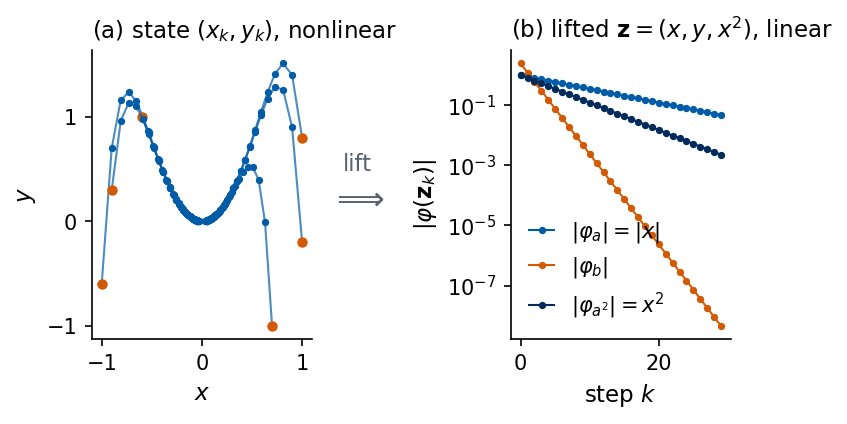

In [5]:
def lifting_figure():
    """(a) curved trajectories of the nonlinear map in the (x, y) plane; (b) the three Koopman
    eigenfunctions along one trajectory, straight lines on a log axis."""
    starts = jnp.array([[1.0, 0.8], [-1.0, -0.6], [0.7, -1.0], [-0.6, 1.0], [1.0, -0.2], [-0.9, 0.3]])
    _, tr = jax.lax.scan(lambda s, _: (lift_map(s), s), starts, None, length=30)          # (30, 6, 2)
    tr = np.asarray(tr)
    with mpl.rc_context(SLIDE_RC):
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(5.5, 2.5), gridspec_kw={"wspace": 0.9})
        for j in range(tr.shape[1]):
            ax1.plot(tr[:, j, 0], tr[:, j, 1], "-", color=UJBlue, lw=1.0, alpha=0.7)
            ax1.plot(tr[:, j, 0], tr[:, j, 1], "o", color=UJBlue, ms=2.5)
            ax1.plot(tr[0, j, 0], tr[0, j, 1], "o", color=DSOrange, ms=4)
        ax1.set_xlabel(r"$x$"); ax1.set_ylabel(r"$y$")
        ax1.set_title(r"(a) state $(x_k,y_k)$, nonlinear", loc="left")
        k = np.arange(tr.shape[0]); s = tr[:, 0]                        # trajectory from (1, 0.8)
        for vals, lab, col in [(np.abs(s[:, 0]), r"$|\varphi_a|=|x|$", UJBlue),
                               (np.abs(np.asarray(phi_b(jnp.asarray(s)))), r"$|\varphi_b|$", DSOrange),
                               (s[:, 0]**2, r"$|\varphi_{a^2}|=x^2$", UJNavy)]:
            ax2.semilogy(k, vals, "o-", ms=2.5, lw=1.0, color=col, label=lab)
        ax2.set_xlabel(r"step $k$"); ax2.set_ylabel(r"$|\varphi(\mathbf{z}_k)|$")
        ax2.set_title(r"(b) lifted $\mathbf{z}=(x,y,x^2)$, linear", loc="left")
        ax2.legend(loc="lower left", handlelength=1.2)
        # arrow between the panels, placed in figure coordinates halfway between the two axes boxes
        x_mid = 0.5 * (ax1.get_position().x1 + ax2.get_position().x0) - 0.065
        fig.text(x_mid, 0.56, "lift", ha="center", fontsize=11, color=UJGray)
        fig.text(x_mid, 0.46, r"$\Longrightarrow$", ha="center", fontsize=16, color=UJGray)
    return fig

fig = lifting_figure(); save(fig, "fig_lifting"); plt.show()

<hr/>
## 2. The Koopman operator

Let $\mathbf S_t\colon\mathcal M\to\mathcal M$ be the flow of the autonomous system $\dot{\mathbf x}=\mathbf F(\mathbf x)$ on the state space $\mathcal M\subseteq\mathbb R^n$, so that $\mathbf x(t)=\mathbf S_t(\mathbf x(0))$. An *observable* is any function $g\colon\mathcal M\to\mathbb C$, such as one coordinate, the energy, or the quantity a detector records. Observables form a vector space of functions, for instance $L^2(\mathcal M)$. The Koopman operator $\mathcal K_t$ acts on this space by composition with the flow [Koopman 1931, Brunton *et al.* 2022],
$$
(\mathcal K_t g)(\mathbf x)=g\bigl(\mathbf S_t(\mathbf x)\bigr).
$$
It is linear for any flow, because composition is linear in $g$,
$$
\mathcal K_t(\alpha g_1+\beta g_2)=\alpha\,\mathcal K_t g_1+\beta\,\mathcal K_t g_2 ,
$$
and it inherits the semigroup property $\mathcal K_{t+s}=\mathcal K_t\mathcal K_s$ from $\mathbf S_{t+s}=\mathbf S_t\circ\mathbf S_s$. For a map $\mathbf x_{k+1}=\mathbf S(\mathbf x_k)$, such as the one of Section 1 or a flow sampled with step $\Delta t$, the same definition gives one operator $\mathcal K$ with $(\mathcal Kg)(\mathbf x)=g(\mathbf S(\mathbf x))$. The nonlinearity of $\mathbf F$ has moved into the size of the space on which $\mathcal K_t$ acts, which is infinite-dimensional.

Differentiating $g(\mathbf S_t(\mathbf x))$ at $t=0$ gives the generator of the semigroup, the derivative along the vector field,
$$
L_{\mathbf F}\,g(\mathbf x)=\mathbf F(\mathbf x)\cdot\nabla g(\mathbf x),\qquad \mathcal K_t=e^{tL_{\mathbf F}} .
$$
An eigenfunction $\varphi_j$ of the generator with eigenvalue $\mu_j$ satisfies $L_{\mathbf F}\varphi_j=\mu_j\varphi_j$ and therefore $\mathcal K_t\varphi_j=e^{\mu_jt}\varphi_j$. Along every trajectory such an observable only grows, decays or rotates in the complex plane at a fixed rate, $\varphi_j(\mathbf x(t))=e^{\mu_jt}\varphi_j(\mathbf x(0))$. If an observable lies in the span of eigenfunctions, $g=\sum_jc_j\varphi_j$, its whole future follows from the coefficients,
$$
g\bigl(\mathbf x(t)\bigr)=\sum_j c_j\,e^{\mu_jt}\,\varphi_j\bigl(\mathbf x(0)\bigr).
$$
This modal expansion is the infinite-dimensional version of diagonalising $K$ in Section 1.

The harmonic oscillator $\dot x=v$, $\dot v=-\omega^2x$ gives the simplest case. The observable $\varphi_+(x,v)=x+\mathrm iv/\omega$ satisfies $L_{\mathbf F}\varphi_+=v-\mathrm i\omega x=-\mathrm i\omega\,\varphi_+$, so $\mu_\pm=\mp\mathrm i\omega$, and the coordinate $x=(\varphi_++\varphi_-)/2$ evolves as $x(t)=\mathrm{Re}[e^{-\mathrm i\omega t}\varphi_+(x_0,v_0)]$. The energy $E=\tfrac12v^2+\tfrac12\omega^2x^2=\tfrac12\omega^2\varphi_+\varphi_-$ is an eigenfunction with $\mu=0$, and products of eigenfunctions are eigenfunctions with summed eigenvalues. For a nonlinear flow the eigenfunctions are nonlinear functions of the state. The Stuart–Landau oscillator in polar coordinates, $\dot r=r(1-r^2)$, $\dot\theta=\omega+\beta_{\mathrm{SL}}(1-r^2)$, has the limit cycle $r=1$ and the exact phase eigenfunction $\varphi(r,\theta)=e^{\mathrm i(\theta-\beta_{\mathrm{SL}}\ln r)}$ with $\mu=\mathrm i\omega$. Its level sets spiral when $\beta_{\mathrm{SL}}\neq0$, so the nonlinearity of the flow sits in the shape of $\varphi$. We check both eigenfunctions symbolically with the generator, and the oscillator one also numerically by integrating the flow.

In [6]:
x, v, r, th = sp.symbols("x v r theta", real=True)
w, bSL, t = sp.symbols("omega beta_SL t", positive=True)

# harmonic oscillator: F = (v, -w^2 x)
F_osc = sp.Matrix([v, -w**2 * x])
L = lambda F, g, coords: sum(Fi * sp.diff(g, ci) for Fi, ci in zip(F, coords))   # generator F . grad g
phi_p = x + sp.I * v / w
print("oscillator  L_F phi_+ / phi_+ =", sp.simplify(L(F_osc, phi_p, (x, v)) / phi_p))
E = (v**2 + w**2 * x**2) / 2
print("oscillator  L_F E =", sp.simplify(L(F_osc, E, (x, v))))

# Stuart-Landau in polar coordinates: F = (r(1 - r^2), w + beta_SL (1 - r^2))
F_sl = sp.Matrix([r * (1 - r**2), w + bSL * (1 - r**2)])
phi_sl = sp.exp(sp.I * (th - bSL * sp.log(r)))
print("Stuart-Landau  L_F phi / phi =", sp.simplify(L(F_sl, phi_sl, (r, th)) / phi_sl))

# numerical check: integrate the oscillator with RK4 and compare phi_+(S_t x) with exp(-i w t) phi_+(x)
OMEGA, H_OSC = 1.3, 1e-3
osc_rhs = lambda u: jnp.array([u[1], -OMEGA**2 * u[0]])
u0s = jax.random.normal(jax.random.key(1), (20, 3))[:, :2]                       # 20 initial states
def flow(u, n):
    return jax.lax.fori_loop(0, n, lambda i, q: rk4_step(osc_rhs, q, H_OSC), u)
t_end = 5.0
uT = jax.vmap(lambda u: flow(u, int(t_end / H_OSC)))(u0s)
phi_num = lambda u: u[..., 0] + 1j * u[..., 1] / OMEGA
nums["osc_eigfun_maxdiff"] = float(jnp.abs(phi_num(uT) - jnp.exp(-1j * OMEGA * t_end) * phi_num(u0s)).max())
print(f"max |phi_+(S_t x) - exp(-i w t) phi_+(x)| at t = {t_end}: {nums['osc_eigfun_maxdiff']:.1e}")

oscillator  L_F phi_+ / phi_+ = -I*omega
oscillator  L_F E = 0
Stuart-Landau  L_F phi / phi = I*omega


max |phi_+(S_t x) - exp(-i w t) phi_+(x)| at t = 5.0: 4.7e-13


The generator returns $-\mathrm i\omega$ for the oscillator, $0$ for its energy and $\mathrm i\omega$ for the Stuart–Landau phase eigenfunction, for all parameter values. The numerical flow reproduces $\mathcal K_t\varphi_+=e^{-\mathrm i\omega t}\varphi_+$ to $5\times10^{-13}$, the accuracy of the fourth-order Runge–Kutta (RK4) integrator with step $10^{-3}$.

Eigenfunctions are generally unknown in advance, and a generic nonlinear system needs infinitely many of them to represent an arbitrary observable. For a chaotic system with mixing dynamics the Koopman operator has a continuous spectrum, so the expansion over discrete eigenfunctions does not exist for most observables. In that case no finite set of observables is mapped into its own span, and every finite linear model is an approximation whose error accumulates under iteration [Brunton *et al.* 2022]. Section 4 shows this for the Lorenz signal.

<hr/>
## 3. Dynamic mode decomposition and its extension

Dynamic mode decomposition (DMD) fits a linear map to snapshot pairs [Schmid 2010]. Given $N$ pairs $(\mathbf x_i,\mathbf y_i)$ with $\mathbf y_i=\mathbf S(\mathbf x_i)$, arranged as columns of $X,Y\in\mathbb R^{n\times N}$, DMD seeks the matrix $K_{\mathrm{DMD}}\in\mathbb R^{n\times n}$ that minimises the Frobenius norm $\|Y-KX\|_F$. The minimiser is
$$
K_{\mathrm{DMD}}=YX^+ ,
$$
with $X^+$ the Moore–Penrose pseudoinverse. Through the singular value decomposition $X=U\Sigma V^\top$ the pseudoinverse is $X^+=V\Sigma^{-1}U^\top$, where singular values below a relative tolerance $\epsilon_{\mathrm{rel}}\,\sigma_{\max}$ are dropped. DMD is the Koopman approximation with the identity dictionary, in which the observables are the state coordinates themselves. It is exact for linear dynamics.

Below is the DMD implementation in JAX, with $X$ of shape $(n,N)$ and $Y$ of shape $(n,N)$, followed by a comparison with `numpy.linalg.lstsq`, which solves the transposed problem $X^\top K^\top\approx Y^\top$. The data are 500 snapshot pairs of the map of Section 1 with $(x,y)$ uniform in $[-1,1]^2$.

In [7]:
def pinv_svd(X, rtol=1e-12):
    """Moore-Penrose pseudoinverse of X (n, N) via the SVD; singular values below rtol * s_max are dropped."""
    U, s, Vt = jnp.linalg.svd(X, full_matrices=False)
    s_inv = jnp.where(s > rtol * s[0], 1.0 / s, 0.0)
    return (Vt.T * s_inv) @ U.T                                   # (N, n)

@jax.jit
def dmd(X, Y):
    """DMD matrix K = Y X^+ for snapshot matrices X, Y of shape (n, N)."""
    return Y @ pinv_svd(X)

# snapshot pairs of the nonlinear map, states as columns
s_tr = jax.random.uniform(jax.random.key(2), (500, 2), minval=-1.0, maxval=1.0)
X_xy, Y_xy = s_tr.T, lift_map(s_tr).T                              # (2, 500) each
K_dmd = dmd(X_xy, Y_xy)
K_np = np.linalg.lstsq(np.asarray(X_xy).T, np.asarray(Y_xy).T, rcond=None)[0].T
nums["dmd_vs_lstsq_lifting"] = float(np.abs(np.asarray(K_dmd) - K_np).max())
nums["dmd_xy_eigs"] = sorted(np.linalg.eigvals(np.asarray(K_dmd)).real.tolist())
print("K_DMD on (x, y) =\n", np.round(np.asarray(K_dmd), 4))
print(f"max |K_JAX - K_numpy| = {nums['dmd_vs_lstsq_lifting']:.1e}")

K_DMD on (x, y) =
 [[ 0.9    -0.    ]
 [ 0.0246  0.4708]]
max |K_JAX - K_numpy| = 1.0e-16


The JAX and `numpy` matrices agree to $1\times10^{-16}$. The DMD matrix on $(x,y)$ has eigenvalues 0.471, 0.900. The value $0.9=a$ is recovered, because $x$ alone is closed under the map. The second eigenvalue differs from $b=0.5$, because the least-squares fit absorbs the part of $c\,x^2$ that correlates with $y$ on the sampled states.

Extended DMD (EDMD) replaces the state by a dictionary of $d$ observables $\boldsymbol\psi(\mathbf x)=(\psi_1(\mathbf x),\dots,\psi_d(\mathbf x))^\top$ [Williams *et al.* 2015]. With the uncentred covariance matrices
$$
A=\frac1N\sum_{i=1}^N\boldsymbol\psi(\mathbf x_i)\boldsymbol\psi(\mathbf x_i)^\top,\qquad
G=\frac1N\sum_{i=1}^N\boldsymbol\psi(\mathbf y_i)\boldsymbol\psi(\mathbf x_i)^\top ,
$$
the least-squares propagator on the dictionary, with a ridge penalty $\beta\ge0$, is
$$
K=G\,(A+\beta I)^{-1}.
$$
For $\beta=0$ this equals DMD applied to the lifted snapshots $\boldsymbol\psi(\mathbf x_i)$. A finite dictionary is generally not mapped into its own span by the Koopman operator. The part of $\mathcal K\boldsymbol\psi$ that $K\boldsymbol\psi$ misses is the closure error
$$
\mathbf r(\mathbf x)=\boldsymbol\psi\bigl(\mathbf S(\mathbf x)\bigr)-K\boldsymbol\psi(\mathbf x),
$$
which vanishes for all $\mathbf x$ if and only if the span of the dictionary is invariant. We fit EDMD with three dictionaries and evaluate the root-mean-square (RMS) of each component of $\mathbf r$ on 2000 fresh states. The dictionary $(x,y)$ is DMD, $(x,y,x^2)$ is the invariant set of Section 1, and $(x,y,x^2,y^2)$ adds $y^2$, whose image $(b\,y+c\,x^2)^2$ contains $x^2y$ and $x^4$ outside the span.

In [8]:
@partial(jax.jit, static_argnums=0)
def edmd(dictionary, Xs, Ys, beta=0.0):
    """EDMD propagator K = G (A + beta I)^{-1}.  Xs, Ys: states (N, n); dictionary: (N, n) -> (N, d)."""
    PX, PY = dictionary(Xs), dictionary(Ys)                       # (N, d)
    N = PX.shape[0]
    A = PX.T @ PX / N                                              # (d, d) uncentred covariance
    G = PY.T @ PX / N                                              # (d, d) cross-covariance
    return jnp.linalg.solve((A + beta * jnp.eye(A.shape[0])).T, G.T).T   # G (A + beta I)^{-1}

dictionaries = {
    "xy":     lambda s: s,
    "xyx2":   lift_obs,
    "xyx2y2": lambda s: jnp.concatenate([lift_obs(s), s[:, 1:2]**2], axis=1),
}
s_te = jax.random.uniform(jax.random.key(3), (2000, 2), minval=-1.0, maxval=1.0)   # fresh test states
K_edmd, closure = {}, {}
for name, dic in dictionaries.items():
    K = edmd(dic, s_tr, lift_map(s_tr))
    r_test = dic(lift_map(s_te)) - dic(s_te) @ K.T               # closure error r(x) on test states, (2000, d)
    K_edmd[name] = K
    closure[name] = np.sqrt(np.mean(np.asarray(r_test)**2, axis=0)).tolist()
    print(f"dictionary {name:7s}: RMS closure error per component", np.array2string(np.array(closure[name]), precision=3))
nums["closure_rms"] = closure
nums["edmd_K_maxdiff_exact"] = float(jnp.abs(K_edmd["xyx2"] - K_lift).max())
print(f"max |K_EDMD - K| for the dictionary (x, y, x^2): {nums['edmd_K_maxdiff_exact']:.1e}")
# EDMD with beta = 0 is DMD on the lifted snapshots
print("EDMD(beta=0) equals DMD on lifted snapshots:",
      bool(jnp.allclose(K_edmd["xyx2"], dmd(lift_obs(s_tr).T, lift_obs(lift_map(s_tr)).T), atol=1e-10)))

dictionary xy     : RMS closure error per component [1.317e-16 4.450e-01]


dictionary xyx2   : RMS closure error per component [1.316e-16 5.809e-16 1.530e-16]


dictionary xyx2y2 : RMS closure error per component [2.629e-16 2.527e-16 2.573e-16 1.927e-01]
max |K_EDMD - K| for the dictionary (x, y, x^2): 8.9e-16


EDMD(beta=0) equals DMD on lifted snapshots: True


The dictionary $(x,y,x^2)$ recovers the matrix $K$ of Section 1 to $9\times10^{-16}$, and its closure error is at round-off level, at most $6\times10^{-16}$. The identity dictionary $(x,y)$ leaves an RMS error of 0.445 in the $y$ component, which is the term $c\,x^2$ projected out of the span. A larger dictionary does not help by itself. Adding $y^2$ keeps the first three components closed (error at most $3\times10^{-16}$) and introduces an error of 0.193 in the new component, since its image leaks out of the span. Closure is a property of the subspace spanned by the dictionary, and its size alone does not decide it.

Iterating the fitted matrices from one initial state shows how the closure error accumulates in a forecast. The plotted quantity is $y_k$ for the true map and the readout $\mathbf e_2^\top K^k\boldsymbol\psi(\mathbf x_0)$ for the two fitted matrices.

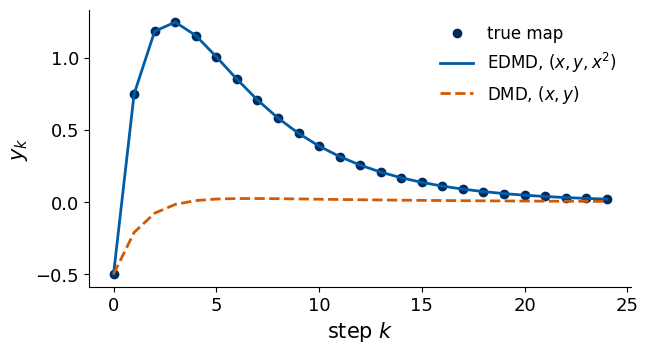

max |y_k - EDMD forecast| = 2.9e-15,  max |y_k - DMD forecast| = 1.265


In [9]:
s_init = jnp.array([[1.0, -0.5]])
_, tr_true = jax.lax.scan(lambda s, _: (lift_map(s), s), s_init, None, length=25)
y_true = np.asarray(tr_true[:, 0, 1])
roll = lambda K, z0: np.array([(jnp.linalg.matrix_power(K, m) @ z0)[1] for m in range(25)])
y_xy = roll(K_edmd["xy"], s_init[0])
y_xyx2 = roll(K_edmd["xyx2"], lift_obs(s_init)[0])
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(y_true, "o", color=UJNavy, label="true map")
ax.plot(y_xyx2, "-", color=UJBlue, label=r"EDMD, $(x,y,x^2)$")
ax.plot(y_xy, "--", color=DSOrange, label=r"DMD, $(x,y)$")
ax.set_xlabel(r"step $k$"); ax.set_ylabel(r"$y_k$"); ax.legend(); plt.show()
print(f"max |y_k - EDMD forecast| = {np.abs(y_true - y_xyx2).max():.1e},  max |y_k - DMD forecast| = {np.abs(y_true - y_xy).max():.3f}")

<hr/>
## 4. Delay dynamic mode decomposition

A measured signal $s_k=h(\mathbf x_k)$ is one observable of an unknown state, so neither DMD on the state nor a hand-made dictionary can be applied directly. The delay vector of window length $L$,
$$
\mathbf u_k=(s_{k-L+1},\dots,s_{k-1},s_k)^\top\in\mathbb R^L ,
$$
contains the same observable evaluated at time-lagged states, $s_{k-j}=h(\mathbf x_{k-j})$. For an invertible map this is $(\mathcal K^{-j}h)(\mathbf x_k)$, so the delay vector is a dictionary generated by the Koopman operator from the single measurement $h$. Takens' theorem guarantees that for $L$ large enough this vector embeds the attractor [Takens 1981], and the Koopman reading adds that a linear map on $\mathbf u_k$ is a finite Koopman approximation. Stacking the delay vectors as columns gives a Hankel matrix, constant along its antidiagonals, which is why the method is also called Hankel DMD. The fitted matrix is $K=YX^+$ with $X=[\mathbf u_{L-1},\dots,\mathbf u_{N-2}]$ and $Y=[\mathbf u_L,\dots,\mathbf u_{N-1}]$, and a forecast iterates $\mathbf u\mapsto K\mathbf u$ and reads the last component.

We apply the method to three signals of $N=4000$ samples each, rescaled to $[0,1]$ with the minimum and maximum of the training block (the first 3000 samples) and centred with its mean. The two-harmonic signal $s(t)=\sin t+\tfrac12\sin2t$ sampled with $\Delta t=0.05$ spans four Fourier modes and is the simplest periodic case. The Mackey–Glass signal with delay $\tau_{\mathrm{MG}}=15$ is a limit cycle with many harmonics, and the Lorenz $x$ signal with $\Delta t=0.02$ is chaotic. The window length must cover the slowest structure of the signal. We use $L=20$ for the two-harmonic and Lorenz signals and $L=100$ for Mackey–Glass, longer than its period, which we measure from the gaps between successive maxima.

In [10]:
N_TWO_DT, N_LOR_DT = 0.05, 0.02
t_two = np.arange(N_SAMPLES) * N_TWO_DT
raw = {"two": np.sin(t_two) + 0.5 * np.sin(2 * t_two),
       "mg15": mackey_glass(15, N_SAMPLES),
       "lorenz": np.asarray(lorenz_trajectory(N_SAMPLES))[:, 0]}
DT = {"two": N_TWO_DT, "mg15": 1.0, "lorenz": N_LOR_DT}
L_WIN = {"two": 20, "mg15": 100, "lorenz": 20}
LABEL = {"two": "two harmonics", "mg15": r"Mackey–Glass $\tau_{\rm MG}=15$", "lorenz": r"Lorenz $x$"}

sig = {}
for k, s in raw.items():
    s01 = rescale01(s)
    sig[k] = s01 - s01[:N_TRAIN].mean()                 # centred with the training mean

# period of the Mackey-Glass limit cycle from the gaps between local maxima
s = raw["mg15"]
peaks = np.where((s[1:-1] > s[:-2]) & (s[1:-1] > s[2:]))[0] + 1
gaps = np.diff(peaks)
print("gaps between successive maxima (samples), first 9:", gaps[:9], "| last 9:", gaps[-9:])
nums["mg15_peak_gaps"] = gaps[:3].tolist()
three = gaps[:-2] + gaps[1:-1] + gaps[2:]                       # length of three consecutive gaps = one period
print("values of three consecutive gaps:", np.unique(three))
m = (len(peaks) - 1) // 3                                       # whole periods between the first and a later maximum
nums["mg15_period_samples"] = float((peaks[3 * m] - peaks[0]) / m)
print(f"Mackey-Glass period: {nums['mg15_period_samples']:.3f} samples (average over {m} periods)")

def hankel(s, L):
    """Delay vectors u_k = (s_{k-L+1}, ..., s_k) as columns, shape (L, len(s) - L + 1)."""
    n = len(s) - L + 1
    return jnp.stack([jnp.asarray(s[j:j + n]) for j in range(L)])

gaps between successive maxima (samples), first 9: [11 46 33 11 46 33 11 46 33] | last 9: [46 33 11 46 33 11 46 33 11]
values of three consecutive gaps: [89 90]
Mackey-Glass period: 89.864 samples (average over 44 periods)


The maxima of the Mackey–Glass signal repeat with gaps 11, 46, 33 samples, so the limit cycle has period 89.86 samples and three maxima per period. We fit the delay DMD on the training block of each signal. For each eigenvalue $\lambda_j$ of $K$ the continuous-time rate is $\mu_j=\ln\lambda_j/\Delta t$, whose real part is a growth rate and imaginary part an angular frequency. For the Lorenz signal we also compare the JAX matrix with `numpy.linalg.lstsq`.

In [11]:
K_hank, eigs = {}, {}
for k in sig:
    U = hankel(sig[k][:N_TRAIN], L_WIN[k])                   # (L, n) delay vectors of the training block
    K_hank[k] = dmd(U[:, :-1], U[:, 1:])
    eigs[k] = np.linalg.eigvals(np.asarray(K_hank[k]))
    print(f"{k:7s} L = {L_WIN[k]:3d}   max |lambda| = {np.abs(eigs[k]).max():.5f}")

U = hankel(sig["lorenz"][:N_TRAIN], 20)
K_np = np.linalg.lstsq(np.asarray(U[:, :-1]).T, np.asarray(U[:, 1:]).T, rcond=None)[0].T
nums["dmd_vs_lstsq_lorenz"] = float(np.abs(np.asarray(K_hank["lorenz"]) - K_np).max())
sv = np.linalg.svd(np.asarray(U[:, :-1]), compute_uv=False)
nums["lorenz_hankel_sv_ratio"] = float(sv[-1] / sv[0])
print(f"Lorenz: max |K_JAX - K_numpy| = {nums['dmd_vs_lstsq_lorenz']:.1e}; "
      f"smallest / largest singular value of X = {nums['lorenz_hankel_sv_ratio']:.1e}")

# two harmonics: eigenvalues with |lambda| > 0.5 sit on the unit circle at frequencies 0, +-1, +-2
ev = eigs["two"][np.abs(eigs["two"]) > 0.5]
mu = np.log(ev.astype(complex)) / DT["two"]
nums["two_imag_mu"] = sorted(np.round(mu.imag, 6).tolist())
nums["two_lam_mod_max_dev"] = float(np.abs(np.abs(ev) - 1).max())
print("two harmonics: Im mu of the unit-circle eigenvalues:", nums["two_imag_mu"],
      f"| max ||lambda| - 1| = {nums['two_lam_mod_max_dev']:.1e}",
      f"| other eigenvalues: max |lambda| = {np.abs(eigs['two'][np.abs(eigs['two']) <= 0.5]).max():.1e}")

# Mackey-Glass: the slowest oscillating pair against the fundamental frequency 2 pi / period
ev = eigs["mg15"]; mu = np.log(ev.astype(complex))
pair = ev[np.argsort(-np.abs(ev))]
pair = pair[np.abs(pair.imag) > 1e-8]
order = np.argsort(np.abs(np.angle(pair[np.abs(pair) > 0.999])))
fund = pair[np.abs(pair) > 0.999][order][0]
nums["mg15_imag_mu_fund"] = float(abs(np.angle(fund)))
nums["mg15_omega_from_period"] = float(2 * np.pi / nums["mg15_period_samples"])
nums["mg15_lam_max"] = float(np.abs(eigs["mg15"]).max())
print(f"Mackey-Glass: smallest |Im mu| among |lambda| > 0.999: {nums['mg15_imag_mu_fund']:.5f}",
      f"| 2 pi / period = {nums['mg15_omega_from_period']:.5f}",
      f"| eigenvalues with |lambda| > 0.999: {(np.abs(ev) > 0.999).sum()} of {len(ev)}")
nums["mg15_n_unit"] = int((np.abs(ev) > 0.999).sum())
nums["lor_lam_max"] = float(np.abs(eigs["lorenz"]).max())
nums["lor_lam_max_mu_re"] = float(np.log(nums["lor_lam_max"]) / DT["lorenz"])
print(f"Lorenz: max |lambda| = {nums['lor_lam_max']:.4f}, slowest decay rate Re mu = {nums['lor_lam_max_mu_re']:.3f} per time unit")

two     L =  20   max |lambda| = 1.00000


mg15    L = 100   max |lambda| = 1.00005
lorenz  L =  20   max |lambda| = 0.95126


Lorenz: max |K_JAX - K_numpy| = 1.9e-07; smallest / largest singular value of X = 2.5e-09
two harmonics: Im mu of the unit-circle eigenvalues: [-2.0, -1.0, 0.0, 1.0, 2.0] | max ||lambda| - 1| = 5.1e-10 | other eigenvalues: max |lambda| = 1.1e-12
Mackey-Glass: smallest |Im mu| among |lambda| > 0.999: 0.06992 | 2 pi / period = 0.06992 | eigenvalues with |lambda| > 0.999: 88 of 100
Lorenz: max |lambda| = 0.9513, slowest decay rate Re mu = -2.498 per time unit


The JAX and `numpy` fits of the Lorenz matrix agree to $2\times10^{-7}$. This is far above round-off because twenty samples spaced by $\Delta t=0.02$ are strongly correlated, and the smallest singular value of $X$ is $3\times10^{-9}$ times the largest, which amplifies round-off errors in the fit. For the two-harmonic signal five eigenvalues lie on the unit circle (deviation of $|\lambda|$ from one at most $5\times10^{-10}$) with imaginary parts $\mathrm{Im}\,\mu$ equal to -2.000000, -1.000000, 0.000000, 1.000000, 2.000000, the frequencies $0,\pm1,\pm2$ of the signal, where the zero frequency carries the small offset left by centring with the training mean. The other fifteen eigenvalues are zero within round-off, since the delay vectors span only five dimensions and the pseudoinverse discards the rest. For Mackey–Glass the spectral radius is 1.00005, 88 of the 100 eigenvalues have $|\lambda|>0.999$, and the slowest oscillating one has angle 0.06992 per sample, against $2\pi/89.86=0.06992$ from the measured period. The Lorenz eigenvalues all lie inside the circle, with spectral radius 0.951.

The figure shows the eigenvalues in the complex plane together with the unit circle $|\lambda|=1$.

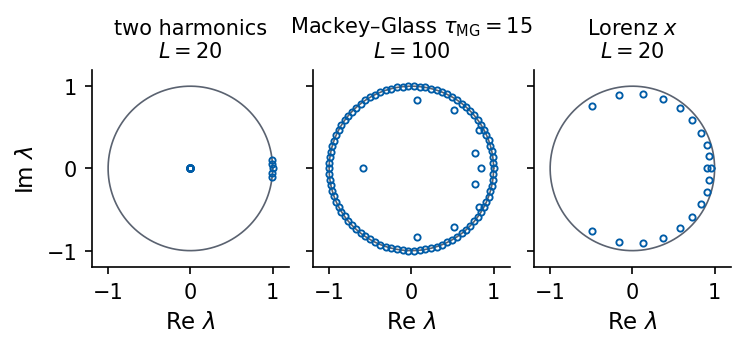

In [12]:
def eig_figure():
    with mpl.rc_context(SLIDE_RC):
        fig, axes = plt.subplots(1, 3, figsize=(5.5, 2.4), sharey=True, gridspec_kw={"wspace": 0.12})
        ph = np.linspace(0, 2 * np.pi, 400)
        for ax, k in zip(axes, ["two", "mg15", "lorenz"]):
            ax.plot(np.cos(ph), np.sin(ph), color=UJGray, lw=0.8)
            ax.plot(eigs[k].real, eigs[k].imag, "o", ms=3.0, mfc="none", mew=0.9, color=UJBlue)
            ax.set_aspect("equal"); ax.set_xlim(-1.2, 1.2); ax.set_ylim(-1.2, 1.2)
            ax.set_xticks([-1, 0, 1]); ax.set_yticks([-1, 0, 1])
            ax.set_title(LABEL[k] + f"\n$L={L_WIN[k]}$", fontsize=10)
            ax.set_xlabel(r"Re $\lambda$")
        axes[0].set_ylabel(r"Im $\lambda$")
    return fig

fig = eig_figure(); save(fig, "fig_delay_dmd_eigs"); plt.show()

The decay of the Lorenz modes should be compared with the time scale on which the Lorenz flow itself loses information about its initial state, the inverse largest Lyapunov exponent $T_\lambda=1/\lambda_1$ (Lab 033). We estimate $\lambda_1$ with the tangent-vector method [Benettin *et al.* 1980]. A tangent vector $\boldsymbol\delta_j$ is propagated with the Jacobian of the RK4 step, obtained by `jax.jvp`, and renormalised to unit length after every step. With $n$ steps of length $h=0.01$,
$$
\lambda_1=\frac{1}{nh}\sum_{j=1}^{n}\ln\|J(\mathbf x_{j-1})\,\boldsymbol\delta_{j-1}\| ,
$$
where $J$ is the Jacobian of one RK4 step. We average over $4000$ time units and split them into four blocks of $1000$ time units to measure the spread.

In [13]:
H_LOR = 0.01
lor_step = lambda u: rk4_step(lorenz_rhs, u, H_LOR)

@partial(jax.jit, static_argnums=2)
def lyap_log_growth(u0, d0, n):
    """Propagate state u and tangent vector d with the RK4 step and its Jacobian; returns ln|d| growth per step."""
    def body(carry, _):
        u, d = carry
        u1, d1 = jax.jvp(lor_step, (u,), (d,))        # u1 = step(u), d1 = J(u) d
        nd = jnp.linalg.norm(d1)
        return (u1, d1 / nd), jnp.log(nd)
    _, logs = jax.lax.scan(body, (u0, d0), None, length=n)
    return logs

u_att = lorenz_trajectory(1)[0]                       # a point on the attractor (after the transient)
logs = np.asarray(lyap_log_growth(u_att, jnp.array([1.0, 0.0, 0.0]), 401000))[1000:]   # drop 10 time units of alignment
blocks = logs.reshape(4, -1).sum(axis=1) / (logs.size / 4 * H_LOR)
nums["lorenz_lyap1"] = float(logs.sum() / (logs.size * H_LOR))
nums["lorenz_lyap1_blocks"] = blocks.tolist()
nums["lorenz_lyap1_block_std"] = float(blocks.std(ddof=1))
nums["lorenz_lyap_time"] = 1.0 / nums["lorenz_lyap1"]
nums["lorenz_lyap_time_samples"] = nums["lorenz_lyap_time"] / N_LOR_DT
print(f"lambda_1 = {nums['lorenz_lyap1']:.4f} per time unit (4000 time units); blocks of 1000:",
      np.round(blocks, 4), f"(std {nums['lorenz_lyap1_block_std']:.4f})")
print(f"Lyapunov time T = 1/lambda_1 = {nums['lorenz_lyap_time']:.3f} time units = {nums['lorenz_lyap_time_samples']:.1f} samples")

lambda_1 = 0.9022 per time unit (4000 time units); blocks of 1000: [0.9041 0.9058 0.8912 0.9078] (std 0.0075)
Lyapunov time T = 1/lambda_1 = 1.108 time units = 55.4 samples


We obtain $\lambda_1=0.902$ per time unit, with block values 0.904, 0.906, 0.891, 0.908 (standard deviation 0.008), so $T_\lambda=1.11$ time units, or 55 samples of the Lorenz signal.

We now iterate each fitted matrix in closed loop, $\mathbf u\mapsto K\mathbf u$, from origins in the test block (the last 1000 samples), so that the forecasts use data the fit never saw. The origins are every fifth sample for which the initial window and 300 forecast steps lie inside the test block. For each lead $h$ we report
$$
\mathrm{NRMSE}(h)=\frac{\bigl\langle(\hat s_{k+h}-s_{k+h})^2\bigr\rangle^{1/2}}{\sigma_{\rm test}},\qquad
A(h)=\frac{\bigl\langle\hat s_{k+h}^{\,2}\bigr\rangle^{1/2}}{\sigma_{\rm test}},
$$
where $\langle\cdot\rangle$ averages over origins $k$, $\hat s_{k+h}$ is the last component of $K^h\mathbf u_k$, and $\sigma_{\rm test}$ is the standard deviation of the test block. The normalised root-mean-square error (NRMSE) equals about one for a forecast that returns the mean, and $A(h)$ measures how far the forecast still moves away from the training mean.

In [14]:
H_ROLL = 300

@partial(jax.jit, static_argnums=2)
def rollout(K, u0, n):
    """Closed-loop forecast: iterate u -> K u for n steps and return the last component, shape (n,)."""
    _, out = jax.lax.scan(lambda u, _: (K @ u, (K @ u)[-1]), u0, None, length=n)
    return out

def rollout_scores(k, K=None, L=None):
    K = K_hank[k] if K is None else K
    L = L_WIN[k] if L is None else L
    s = sig[k]
    U = hankel(s, L)                                    # column j = u_{j+L-1}
    last = np.arange(N_TRAIN + L - 1, N_SAMPLES - H_ROLL, 5)          # index of the last sample in the window
    preds = jax.vmap(lambda u: rollout(K, u, H_ROLL))(U[:, last - L + 1].T)   # (n_origins, H)
    truth = np.stack([s[i + 1:i + 1 + H_ROLL] for i in last])
    sd = s[N_TRAIN:].std()
    nrmse = np.sqrt(np.mean((np.asarray(preds) - truth)**2, axis=0)) / sd
    amp = np.sqrt(np.mean(np.asarray(preds)**2, axis=0)) / sd
    return last, np.asarray(preds), truth, nrmse, amp

scores = {k: rollout_scores(k) for k in sig}
nums["n_origins"] = int(len(scores["lorenz"][0]))
nums["two_nrmse_max"] = float(scores["two"][3].max())
nums["mg15_nrmse_max"] = float(scores["mg15"][3].max())
_, _, _, nr, amp = scores["lorenz"]
h_tl = int(round(nums["lorenz_lyap_time_samples"]))
nums["lor_first_lead_nrmse_half"] = int(np.argmax(nr > 0.5) + 1)
nums["lor_first_time_nrmse_half"] = nums["lor_first_lead_nrmse_half"] * N_LOR_DT
nums["lor_nrmse_at_tlyap"] = float(nr[h_tl - 1])
nums["lor_amp_at_tlyap"] = float(amp[h_tl - 1])
nums["lor_amp_at_2tlyap"] = float(amp[2 * h_tl - 1])
for k in sig:
    print(f"{k:7s} origins {len(scores[k][0])}, NRMSE at h = 1, 10, 50, 300:",
          np.array2string(scores[k][3][[0, 9, 49, 299]], precision=4))
print(f"Lorenz: first lead with NRMSE > 0.5: h = {nums['lor_first_lead_nrmse_half']} "
      f"(t = {nums['lor_first_time_nrmse_half']:.2f}); at h = {h_tl} (one Lyapunov time): NRMSE = {nr[h_tl - 1]:.3f}, "
      f"A = {amp[h_tl - 1]:.3f}; at two Lyapunov times A = {amp[2 * h_tl - 1]:.4f}")

two     origins 137, NRMSE at h = 1, 10, 50, 300: [4.9100e-13 8.9391e-11 2.0399e-08 8.8422e-08]
mg15    origins 121, NRMSE at h = 1, 10, 50, 300: [1.1132e-06 1.6663e-05 1.7019e-05 6.7507e-05]
lorenz  origins 137, NRMSE at h = 1, 10, 50, 300: [4.0961e-05 2.4002e-01 1.0036e+00 1.0146e+00]
Lorenz: first lead with NRMSE > 0.5: h = 14 (t = 0.28); at h = 55 (one Lyapunov time): NRMSE = 0.986, A = 0.118; at two Lyapunov times A = 0.0050


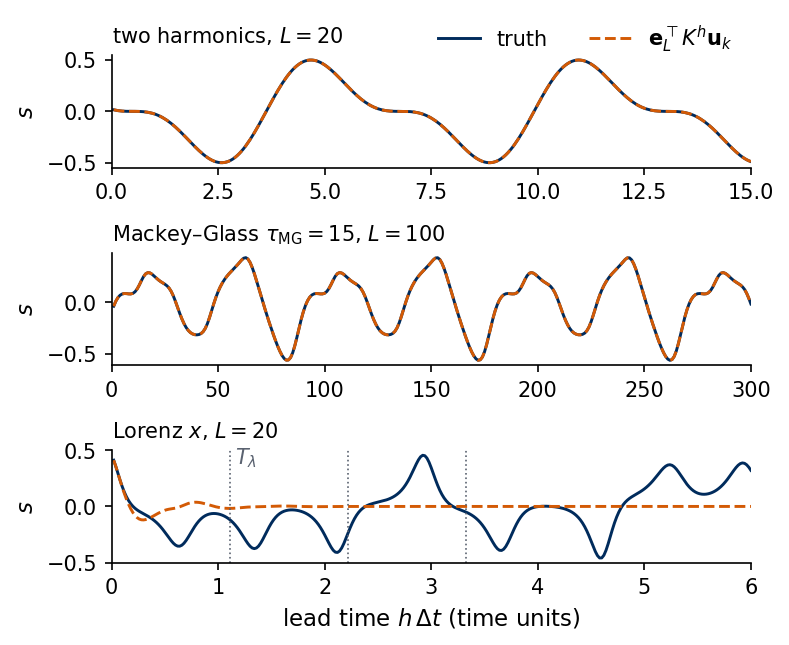

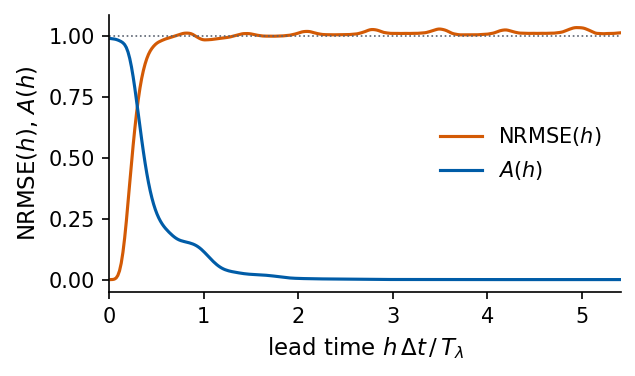

In [15]:
def rollout_figure(i_origin=10):
    with mpl.rc_context(SLIDE_RC):
        fig, axes = plt.subplots(3, 1, figsize=(5.5, 4.4), sharex=False, gridspec_kw={"hspace": 0.75})
        for ax, k in zip(axes, ["two", "mg15", "lorenz"]):
            last, preds, truth, _, _ = scores[k]
            tt = np.arange(1, H_ROLL + 1) * DT[k]
            ax.plot(tt, truth[i_origin], color=UJNavy, lw=1.4, label="truth")
            ax.plot(tt, preds[i_origin], "--", color=DSOrange, lw=1.4, label=r"$\mathbf{e}_L^\top K^h\mathbf{u}_k$")
            ax.set_title(LABEL[k] + f", $L={L_WIN[k]}$", loc="left", fontsize=10)
            ax.set_ylabel(r"$s$")
            if k == "lorenz":
                for m in (1, 2, 3):
                    ax.axvline(m * nums["lorenz_lyap_time"], color=UJGray, lw=0.8, ls=":")
                ax.text(nums["lorenz_lyap_time"] + 0.05, ax.get_ylim()[1] * 0.75, r"$T_\lambda$", color=UJGray, fontsize=10)
            ax.set_xlim(0, tt[-1])
        axes[0].legend(loc="upper right", ncol=2, fontsize=10, bbox_to_anchor=(1.0, 1.45))
        axes[-1].set_xlabel(r"lead time $h\,\Delta t$ (time units)")
    return fig

fig = rollout_figure(); save(fig, "fig_delay_dmd_rollout"); plt.show()

def nrmse_figure():
    _, _, _, nr, amp = scores["lorenz"]
    tt = np.arange(1, H_ROLL + 1) * DT["lorenz"] / nums["lorenz_lyap_time"]
    with mpl.rc_context(SLIDE_RC):
        fig, ax = plt.subplots(figsize=(4.4, 2.4))
        ax.plot(tt, nr, color=DSOrange, label="NRMSE$(h)$")
        ax.plot(tt, amp, color=UJBlue, label="$A(h)$")
        ax.axhline(1.0, color=UJGray, lw=0.8, ls=":")
        ax.set_xlabel(r"lead time $h\,\Delta t\,/\,T_\lambda$"); ax.set_ylabel(r"NRMSE$(h)$, $A(h)$")
        ax.set_xlim(0, tt[-1]); ax.legend(loc="center right")
    return fig

fig = nrmse_figure(); save(fig, "fig_delay_dmd_nrmse"); plt.show()

The rollouts in the figure start from the eleventh origin of the test block. For the two-harmonic signal the largest NRMSE over 300 steps and 137 origins is $9\times10^{-8}$, and for Mackey–Glass it is $7\times10^{-5}$. Both periodic signals lie in a finite invariant subspace of the delay dictionary, and the linear map continues them over the whole horizon. For the Lorenz signal the NRMSE first exceeds 0.5 at lead $h=14$ ($0.28$ time units) and is 0.99 at one Lyapunov time. The forecast amplitude has then dropped to $A=0.12$ and to 0.005 at two Lyapunov times, so the linear rollout relaxes to the training mean within about one Lyapunov time. This damping comes from the closure error of the delay dictionary. The Lorenz flow keeps oscillating on its attractor, and a linear map on 20 delays has only decaying modes to represent it.

The decay is a property of this fit and window. A longer window can give the opposite failure, as the next cell shows for $L=30$.

In [16]:
U30 = hankel(sig["lorenz"][:N_TRAIN], 30)
K30 = dmd(U30[:, :-1], U30[:, 1:])
nums["lor_L30_lam_max"] = float(np.abs(np.linalg.eigvals(np.asarray(K30))).max())
_, _, _, nr30, amp30 = rollout_scores("lorenz", K=K30, L=30)
nums["lor_L30_amp_end"] = float(amp30[-1])
print(f"Lorenz, L = 30: max |lambda| = {nums['lor_L30_lam_max']:.4f}; A(h) at h = 300: {amp30[-1]:.1f}; NRMSE at h = 300: {nr30[-1]:.1f}")

Lorenz, L = 30: max |lambda| = 1.0107; A(h) at h = 300: 19.9; NRMSE at h = 300: 20.0


With $L=30$ one eigenvalue pair has modulus 1.0107, above one, and after 300 steps the forecast amplitude is about 20 times the signal standard deviation. The closure error now produces spurious growth. Damping, growth and phase drift are all possible outcomes of a dictionary that does not close, and which one appears depends on the fitted spectrum [Brunton *et al.* 2022].

<hr/>
## 5. Autoregression as the smallest dictionary

The autoregressive model of order $p$, AR($p$), predicts the next sample as a linear combination of the last $p$ samples,
$$
s_{k+1}=\sum_{i=1}^{p}w_i\,s_{k+1-i}+\varepsilon_{k+1},
$$
with coefficients $w_i$ fitted by least squares and residuals $\varepsilon_{k+1}$. Its dictionary is the delay vector itself, the smallest dictionary that can be built from raw lags. When the delay vectors span $\mathbb R^L$, the first $L-1$ rows of the delay DMD matrix reproduce the shift $u_{j}\mapsto u_{j+1}$, because the rows of $Y$ above the last one are rows of $X$. The last row solves the least-squares problem for $s_{k+1}$, which is the AR($L$) problem. The DMD matrix is therefore the companion matrix of the AR model,
$$
K=\begin{pmatrix}0&1&&\\&\ddots&\ddots&\\&&0&1\\w_L&\cdots&w_2&w_1\end{pmatrix},
$$
and its eigenvalues are the inverses of the roots of $\Phi_p(z)=1-\sum_iw_iz^i$. The classical stationarity condition, all roots of $\Phi_p$ outside the unit circle, is the condition that all Koopman eigenvalues of this dictionary lie inside it.

We fit AR(20) on the training block of the Lorenz signal with a JAX least-squares solve, with `statsmodels` `AutoReg` without a constant (the signal is centred), and compare both with the last row of the delay DMD matrix of Section 4.

In [17]:
p = 20
s_tr_lor = sig["lorenz"][:N_TRAIN]
lags = np.stack([s_tr_lor[p - i:N_TRAIN - i] for i in range(1, p + 1)], axis=1)   # column i-1 holds s_{k+1-i}
target = s_tr_lor[p:]                                                            # s_{k+1}
w_jax = jnp.linalg.lstsq(jnp.asarray(lags), jnp.asarray(target))[0]             # (w_1, ..., w_p)
w_sm = AutoReg(s_tr_lor, lags=p, trend="n").fit().params

K = np.asarray(K_hank["lorenz"])
last_row = K[-1, ::-1]                                    # (w_1, ..., w_L) in the oldest-first ordering
nums["ar_vs_dmd_lastrow"] = float(np.abs(np.asarray(w_jax) - last_row).max())
nums["ar_vs_statsmodels"] = float(np.abs(np.asarray(w_jax) - w_sm).max())
nums["dmd_upper_rows_vs_shift"] = float(np.abs(K[:-1] - np.eye(p, k=1)[:-1]).max())
print(f"max |w_AR(JAX) - last row of K_DMD| = {nums['ar_vs_dmd_lastrow']:.1e}")
print(f"max |w_AR(JAX) - w_AR(statsmodels)| = {nums['ar_vs_statsmodels']:.1e}")
print(f"max |upper rows of K_DMD - shift| = {nums['dmd_upper_rows_vs_shift']:.1e}")

# companion matrix of the AR coefficients: shift in the upper rows, (w_p, ..., w_1) in the last row
C = np.eye(p, k=1); C[-1] = np.asarray(w_jax)[::-1]
nums["companion_vs_dmd"] = float(np.abs(C - K).max())
nums["companion_specrad"] = float(np.abs(np.linalg.eigvals(C)).max())
print(f"max |C_AR - K_DMD| = {nums['companion_vs_dmd']:.1e}; spectral radius of C_AR = {nums['companion_specrad']:.4f}")
# roots of Phi_p(z) = 1 - sum w_i z^i against inverse eigenvalues of the companion matrix
roots = np.roots(np.concatenate([-np.asarray(w_jax)[::-1], [1.0]]))        # highest power first
inv_eigs = 1.0 / np.linalg.eigvals(C)
dist = max(np.abs(roots - z).min() for z in inv_eigs)
nums["ar_roots_vs_inv_eigs"] = float(dist)
nums["ar_min_root_modulus"] = float(np.abs(roots).min())
print(f"max distance between roots of Phi_p and 1/lambda: {dist:.1e}; smallest |root| = {np.abs(roots).min():.4f}")

max |w_AR(JAX) - last row of K_DMD| = 5.9e-07
max |w_AR(JAX) - w_AR(statsmodels)| = 1.3e-07
max |upper rows of K_DMD - shift| = 1.1e-09
max |C_AR - K_DMD| = 5.9e-07; spectral radius of C_AR = 0.9487
max distance between roots of Phi_p and 1/lambda: 2.1e-08; smallest |root| = 1.0541


The three fits agree, with the JAX coefficients equal to the last row of the DMD matrix to $6\times10^{-7}$ and to the `statsmodels` coefficients to $1\times10^{-7}$. The upper rows of the DMD matrix equal the shift to $1\times10^{-9}$, and the roots of $\Phi_{20}$ coincide with the inverse eigenvalues of the companion matrix to $2\times10^{-8}$. The smallest root modulus is 1.0541, larger than one, so the fitted AR(20) model is stationary and its free run decays to the mean, as seen in Section 4.

The AR model thus closes the Koopman operator on the linear span of past samples, and its residual $\varepsilon_{k+1}$ is the last component of the closure error. A richer dictionary keeps the lags and adds nonlinear functions of them. NVAR adds all quadratic monomials $s_{k-i}s_{k-j}$ of the delay vector and fits a linear readout on them [Gauthier *et al.* 2021]. Lab 034 compared AR, its moving-average extensions and NVAR on the signals of the course. In the Koopman picture NVAR is AR with a larger dictionary.

<hr/>
## Summary

The Koopman operator $(\mathcal K_tg)(\mathbf x)=g(\mathbf S_t(\mathbf x))$ acts linearly on observables for any flow, and its eigenfunctions evolve as $\varphi_j(\mathbf x(t))=e^{\mu_jt}\varphi_j(\mathbf x(0))$. When a finite set of observables is mapped into its own span, the dynamics on that set is a matrix, and forecasting is a matrix power. The map $x_{k+1}=ax_k$, $y_{k+1}=by_k+cx_k^2$ shows this with the three observables $(x,y,x^2)$. The matrix power reproduces direct iteration to $4\times10^{-16}$, and EDMD recovers the matrix from data to $9\times10^{-16}$.

DMD fits $K=YX^+$ on the state, and EDMD fits $K=G(A+\beta I)^{-1}$ on a dictionary. What the dictionary misses is the closure error $\mathbf r(\mathbf x)=\boldsymbol\psi(\mathbf S(\mathbf x))-K\boldsymbol\psi(\mathbf x)$. It vanishes for an invariant dictionary and is nonzero for both the smaller dictionary $(x,y)$ and the larger dictionary $(x,y,x^2,y^2)$ of the example.

For a measured scalar signal the delay vector is a dictionary generated from one observable. Delay DMD places the eigenvalues of the two-harmonic signal on the unit circle at the signal frequencies and continues it, as well as the Mackey–Glass limit cycle with a window longer than its period of 89.86 samples. For the Lorenz signal with $L=20$ all eigenvalues lie inside the unit circle (spectral radius 0.951), and the forecast amplitude falls to 0.12 of the signal standard deviation at one Lyapunov time $T_\lambda=1/\lambda_1=1.11$ time units, with $\lambda_1=0.902$ from the tangent-vector method. A window of $L=30$ instead gives an eigenvalue outside the circle and a growing forecast. Least-squares AR($p$) on raw lags is the last row of the delay DMD matrix, so AR is the Koopman approximation with the smallest dictionary, and NVAR enlarges it by quadratic monomials. The recurrent networks of Lab 036 learn the observables they propagate, in the form of a hidden state, instead of fixing them in advance.

### Exercises

1. Repeat the delay DMD for Mackey–Glass with $\tau_{\mathrm{MG}}=15$ and windows $L=20,40,60,80$. Find the smallest window for which the closed-loop forecast stays on the limit cycle for 300 steps and compare it with the period.
2. Add the monomials $x^2y$ and $x^4$ to the dictionary $(x,y,x^2,y^2)$ of Section 3. Compute the closure error of the enlarged dictionary and derive which further monomials a closed dictionary containing $y^2$ needs.
3. Fit delay DMD to the Lorenz signal with $L=30$ and a ridge penalty $\beta>0$, using $K=G(A+\beta I)^{-1}$ on delay vectors. Find the values of $\beta$ that move the spectral radius below one and report the NRMSE at one Lyapunov time for them.

<hr/>
## References

- B. O. Koopman, *Hamiltonian systems and transformation in Hilbert space*, Proc. Natl. Acad. Sci. USA **17**, 315 (1931), [doi:10.1073/pnas.17.5.315](https://doi.org/10.1073/pnas.17.5.315)
- P. J. Schmid, *Dynamic mode decomposition of numerical and experimental data*, J. Fluid Mech. **656**, 5 (2010), [doi:10.1017/S0022112010001217](https://doi.org/10.1017/S0022112010001217)
- M. O. Williams, I. G. Kevrekidis, C. W. Rowley, *A data-driven approximation of the Koopman operator. Extending dynamic mode decomposition*, J. Nonlinear Sci. **25**, 1307 (2015), [doi:10.1007/s00332-015-9258-5](https://doi.org/10.1007/s00332-015-9258-5)
- S. L. Brunton, M. Budišić, E. Kaiser, J. N. Kutz, *Modern Koopman theory for dynamical systems*, SIAM Rev. **64**, 229 (2022), [doi:10.1137/21M1401243](https://doi.org/10.1137/21M1401243)
- M. Korda, I. Mezić, *Linear predictors for nonlinear dynamical systems. Koopman operator meets model predictive control*, Automatica **93**, 149 (2018), [doi:10.1016/j.automatica.2018.03.046](https://doi.org/10.1016/j.automatica.2018.03.046)
- B. Lusch, J. N. Kutz, S. L. Brunton, *Deep learning for universal linear embeddings of nonlinear dynamics*, Nat. Commun. **9**, 4950 (2018), [doi:10.1038/s41467-018-07210-0](https://doi.org/10.1038/s41467-018-07210-0)
- G. Benettin, L. Galgani, A. Giorgilli, J.-M. Strelcyn, *Lyapunov characteristic exponents for smooth dynamical systems and for Hamiltonian systems. A method for computing all of them. Part 1. Theory*, Meccanica **15**, 9 (1980), [doi:10.1007/BF02128236](https://doi.org/10.1007/BF02128236)
- F. Takens, *Detecting strange attractors in turbulence*, in Dynamical Systems and Turbulence, Lecture Notes in Mathematics **898**, 366 (Springer, 1981), [doi:10.1007/BFb0091924](https://doi.org/10.1007/BFb0091924)
- D. J. Gauthier, E. Bollt, A. Griffith, W. A. S. Barbosa, *Next generation reservoir computing*, Nat. Commun. **12**, 5564 (2021), [doi:10.1038/s41467-021-25801-2](https://doi.org/10.1038/s41467-021-25801-2)

Korda and Mezić extend the lifted linear model to systems with inputs, and Lusch *et al.* learn the dictionary with an autoencoder whose latent dynamics is linear. Both are natural next steps beyond the fixed dictionaries of this notebook.